Groundwater | Case Study

# Flow Case Study: Group 0 Student Template

**Impact of a well doublet on the groundwater flow field.**


## 1. Overview and learning objectives

This notebook is the **worked template** for the flow half of your case study
(group 0's demo scenario). Your own group's copy is a fresh clone of this
notebook + your group's `case_config.yaml` — the model code you call is
identical across groups; what changes is the config (concession wells,
assigned scenario) and the **judgment** you apply to it.

**What is graded:** your group report, your oral presentation, and the modelling work
they rest on — the specific
values you compute, the maps you choose to show, and above all whether your
interpretation is *defensible*. **This notebook itself is not graded** — it
is scaffolding. You are not writing FloPy/MODFLOW code here; the flow model
is built for you by `casestudy_flow_builder`. Your work is: configure,
interpret, hand-compute metrics, explore, and defend.

**The three flow states + the 50% variant:**

| State | What it represents |
|---|---|
| `baseline` | Regional flow field with **no** concession wells |
| `wells_only` | Baseline **+** your group's concession doublet (injection + extraction) at full rate |
| `wells_only_half` | Same doublet at **50%** pumping rate (a sensitivity variant) |
| `wells_plus_scenario` | `wells_only` **+** your group's assigned what-if scenario (river/recharge/CHD/K change) |

All four states share **one grid** (one refine/solve walk) — differences
between them are due to the boundary conditions/parameters you changed, not
to re-meshing artifacts.

### TODO checklist (this notebook)
- [ ] **TODO** Section 2 — fill your group number, authors, title, description in `case_config.yaml`
- [ ] **TODO** Section 3 — justify your scenario's boundary-condition assumption
- [ ] **TODO** Section 8 — hand-compute your group's 3–5 metrics from the provided primitives
- [ ] **TODO** Section 9 — explore your scenario type in the sandbox with a parameter of your own choosing
- [ ] **TODO** Section 10 — write your interpretation & defensibility narrative


*Section 1 complete: learning objectives, state definitions, and the notebook TODO checklist are set*

In [4]:
# Imports -- this cell resolves the support modules; no model code lives here.
import os
import sys
sys.path.append(os.path.abspath('../../../_SUPPORT/src'))

import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import case_utils
import casestudy_flow_builder as cfb
import casestudy_flow_viz as cfv
import casestudy_flow_particles as cfp

print("Imports OK:", cfb.__name__, cfv.__name__, cfp.__name__)


Imports OK: casestudy_flow_builder casestudy_flow_viz casestudy_flow_particles


## 2. Configure your group

Your group's assignment (concession, scenario type) is **fixed** by your
group number in `case_config.yaml` — you do not choose it. What you fill in:
group number, author names, a tailored title, and a description of your
specific problem.

**TODO** (edit `case_config.yaml` in this folder, not this cell):
- `group.number` — your integer group number (0–12)
- `group.authors` — your group members
- `title` — tailor to your concession (keep the core meaning)
- `description` — 2–5 sentences: location context, purpose of the well
  group, why assessing its impact matters

This cell just **loads** the config and derives your output workspace; it
does not edit the YAML for you.


In [5]:
# Load your group's config (edit case_config.yaml above, then re-run this cell).
CASE_YAML = "case_config.yaml"
cfg = case_utils.load_yaml(CASE_YAML)

group_number = cfg["group"]["number"]
# (headless-validation override -- students can ignore this line. The instructor
#  driver validate_flow_groups.py runs this notebook once per group by setting
#  AGM_GROUP_ID, the same hook the transport notebook uses.)
group_number = int(os.environ.get("AGM_GROUP_ID", group_number))

# Refuse to run the wrong group's scenario. Copying template/ to group_07/ and
# leaving group.number at 0 silently runs the demo case; every downstream check
# still passes. Placed AFTER the AGM_GROUP_ID override so the EFFECTIVE group is
# checked. The gates run from template/, whose name is not group_<N>, so this is
# a no-op there.
import sys as _sys; _sys.path.insert(0, '.')
import scratch_io as _sio
_sio.assert_group_folder_matches(group_number)

authors = cfg["group"]["authors"]
title = cfg["title"]
description = cfg["description"]

print(f"Group {group_number}: {title}")
print(f"Authors: {authors}")
print(description)

# Output workspace: output.workspace + group number, expanded (~ -> home dir).
work_dir = Path(cfg["output"]["workspace"] + str(group_number)).expanduser()
work_dir.mkdir(parents=True, exist_ok=True)
print(f"Work dir: {work_dir}")


Group 4: Impact of a dry period on the groundwater flow field.
Authors: ['Grant Kawamoto', 'Mark Schaefer', 'Thomas Bolli']
TODO: Provide 2–5 sentences describing the specific groundwater flow problem for your concession: state the location context, purpose of the well group, and why assessing its impact matters (e.g. potential interference, river depletion, drawdown near sensitive receptors). You will implement the concessioned pumping rates and a 50% pumping variant, then evaluate changes in heads, gradients, and river leakage. GW Flow Problem Proposal: In this project, we aim to study a pair of wells in the Limmat catchment. We will examine the effects of different pumping rates as well as the impact of a predetermined scenario.

Work dir: C:\Users\shado\applied_groundwater_modelling_data\limmat\case_study_group_04


*Section 2 complete: config loaded, group metadata echoed, work_dir resolved*

## 3. Understand your scenario (physics ↔ story)

Every group is assigned one of six scenario *types*. The physical parameter
change and the narrative story behind it are:

| `type` | Parameter change | The story |
|---|---|---|
| `river_conductance` | `conductance_factor` scales RIV conductance | Riverbed **clogging** (↓ f, silt/fine sediment reduces bed-K) or **scouring** (↑ f, high-flow events strip the clogging layer) |
| `river_stage` | `stage_change_m` shifts RIV stage | A **new weir** raises (or a removed one lowers) the river's average water level in a zone |
| `river_width_and_stage` | `width_factor` + `stage_change_factor` | A **river restoration** project widens the channel and typically lowers the average stage |
| `recharge_scale` | `recharge_factor` scales RCHA | **Climate/urban change**: more recharge from urban greening / wetter climate, or less from sealed surfaces / persistent dry periods |
| `chd_head_change` | `chd_head_change_m` shifts CHD heads | A **regional boundary head** change (e.g. a downstream water-management decision outside your domain) |
| `aquifer_transmissivity` | `transmissivity_factor` scales K | **New exploration data** revises the aquifer's hydraulic conductivity estimate |

### Group 0's scenario (this notebook's worked example)

Group 0 is assigned **`chd_head_change`** — *"Demo - Lower outflow boundary by
1 m"* (`chd_head_change_m: -1`). Physically: the downstream constant-head
boundary that represents the regional groundwater/river system beyond your
model domain is lowered by 1 m. This could represent, e.g., a regional
drawdown trend or a downstream abstraction outside the modelled area steepening
the head gradient toward the boundary.

**TODO**: in your report (and again in your presentation), justify why your group's
BC/parameter change is a
reasonable representation of the story assigned to you, and state what
simplifying assumption it makes (e.g. a uniform CHD shift ignores any
transient ramp-up; a uniform conductance factor ignores spatial variability
in clogging).


*Section 3 complete: the physics<->story mapping is taught for all six scenario types; group 0's worked example is fixed*

## 4. Build the four flow states

`build_all_flow_states` performs **one** refine/solve walk (one canonical
DISV grid) and returns all four states (`baseline`, `wells_only`,
`wells_only_half`, `wells_plus_scenario`) solved on that **same** grid. This
matters: any difference you measure between states is a real physical
response to the changed boundary conditions, not a re-meshing artifact.


In [6]:
states = cfb.build_all_flow_states(group_number, work_dir=work_dir)

print(f"Runtime for the full walk: {states['runtime_s']:.1f} s")
print(f"Grid hash (all four states share this): {states['grid_hash']}")
print(f"Refine radius used: {states['refine_radius']}")

# The builder-emitted diagnostics.<state>.json PASS surface for the baseline.
baseline_diag = cfv.read_diagnostics(states["baseline"])
for check_name, result in baseline_diag.items():
    status = "PASS" if result.get("passed") else "FAIL"
    print(f"  [{status}] {check_name}")


Building refined Voronoi grid...
Refined grid: 4371 cells
CHD cells: 18


faithful RIV: reach (0, 2102) retains 1.4% of footprint after overbank filter (< 25%) -- conductance concentrated onto 1 cell(s)


RIV cells: 2602 (records: 2602, Sigma cond: 150332.3)
WEL cells: 238


faithful RIV: reach (0, 2102) retains 1.4% of footprint after overbank filter (< 25%) -- conductance concentrated onto 1 cell(s)


writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model g4_base_ref...
    writing model name file...
    writing package disv...
    writing package npf...
    writing package ic...
    writing package rcha_0...
    writing package chd_0...
INFORMATION: maxbound in ('gwf6', 'chd', 'dimensions') changed to 18 based on size of stress_period_data
    writing package riv_0...
INFORMATION: maxbound in ('gwf6', 'riv', 'dimensions') changed to 2602 based on size of stress_period_data
    writing package wel_0...
INFORMATION: maxbound in ('gwf6', 'wel', 'dimensions') changed to 226 based on size of stress_period_data
    writing package oc...


[casestudy_flow_builder] SKIPPING grid-pin for group 4: committed golden was generated on Linux, building on Windows -- the Triangle/Voronoi mesh differs cross-platform, so this golden is a valid pin only on Linux. The authoritative Windows golden supersedes it here (M2a.5 hub / cross-platform regen).


Budget components found: 7
Reading budget for time = 1.0

Water Balance Summary:
  Total Inflow:  1,654,052.86 m3/d
  Total Outflow: 1,654,047.47 m3/d
  Discrepancy:   5.38 m3/d
  Percent Error: 0.0003%
writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model g4_wells...
    writing model name file...
    writing package disv...
    writing package npf...
    writing package ic...
    writing package rcha_0...
    writing package chd_0...
INFORMATION: maxbound in ('gwf6', 'chd', 'dimensions') changed to 18 based on size of stress_period_data
    writing package riv_0...
INFORMATION: maxbound in ('gwf6', 'riv', 'dimensions') changed to 2602 based on size of stress_period_data
    writing package wel_0...
INFORMATION: maxbound in ('gwf6', 'wel', 'dimensions') changed to 228 based on size of stress_period_data
    writing package oc...
Budget components found: 7
Reading budget for time = 1.0

Water Ba

*Section 4 complete: the four states are built on one canonical grid; diagnostics PASS surface is visible*

## 5. Heads and signed head-change maps

Head maps for the three named states, then **signed head-change** maps:
`wells_only - baseline` (the doublet's effect at full rate), `wells_only_half -
baseline` (the 50% variant), and `wells_plus_scenario - wells_only` (the
scenario's *additional* effect, isolated from the doublet's own response).

> **Sign convention — read this before you quote a number.** These maps are
> `b - a`, so they are **negative where the head falls**. That is the opposite
> sign to *drawdown* as the scratch analysis defines it
> (`scratch_io.compute_drawdown` is `base - compare`, **positive** where the head
> falls). Same physics, opposite sign — so say which one you mean whenever you
> report a value. The figure files keep their historical `drawdown_*` names.


WindowsPath('C:/Users/shado/applied_groundwater_modelling_data/limmat/case_study_group_04/figs/heads_scenario.png')

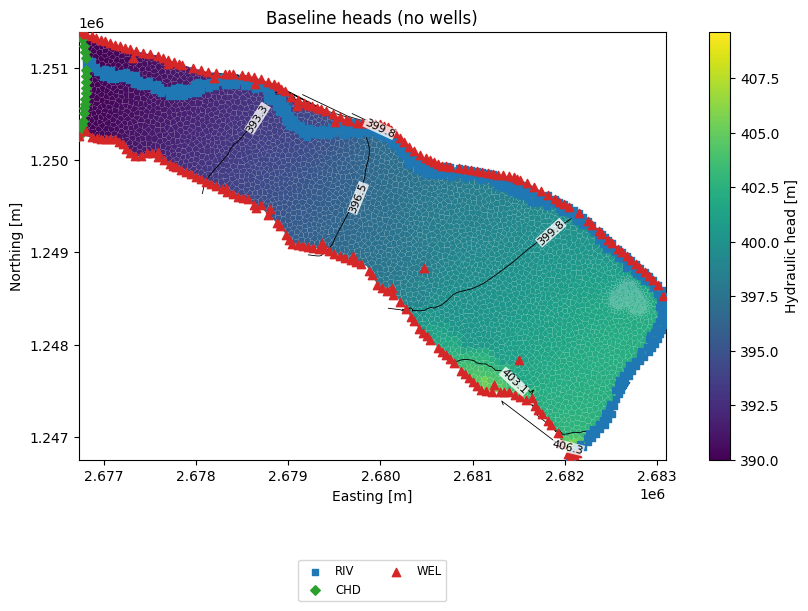

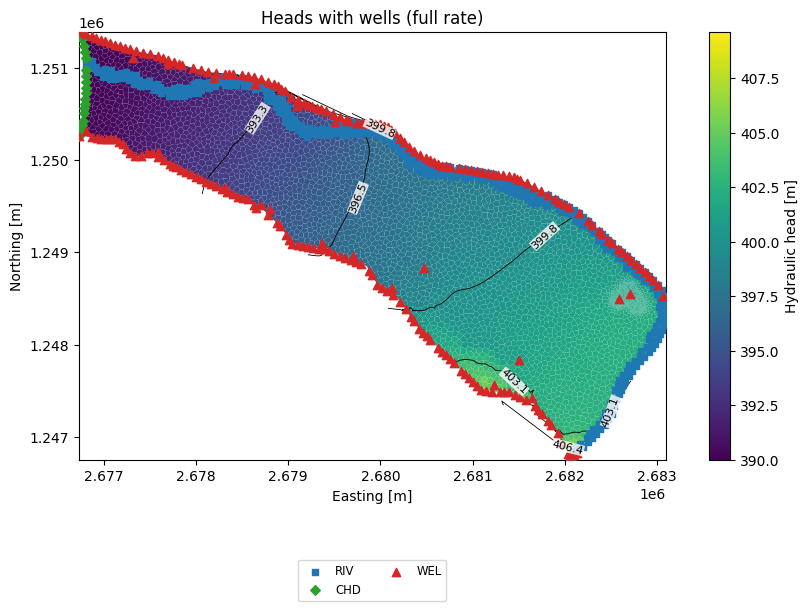

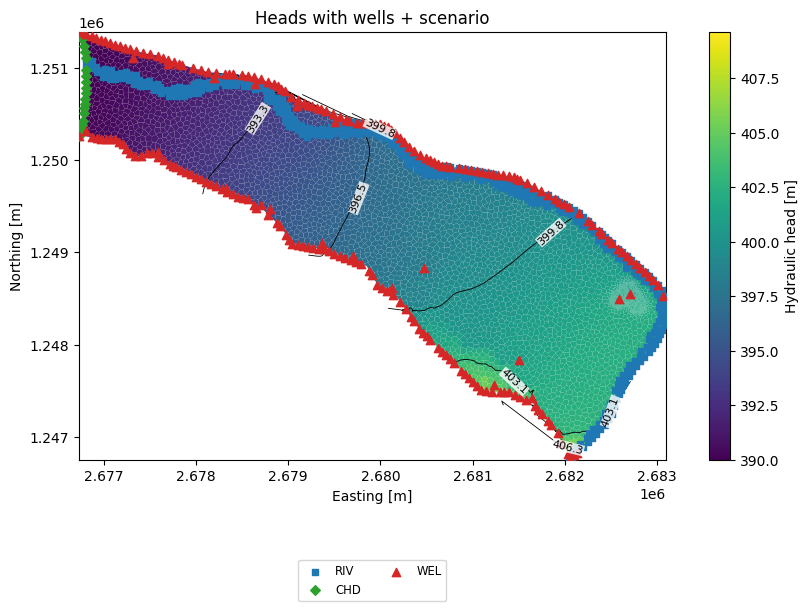

In [7]:
fig, ax = cfv.plot_head_map(states["baseline"], title="Baseline heads (no wells)")
cfv.save_fig(fig, "heads_baseline", out_dir=work_dir)

fig, ax = cfv.plot_head_map(states["wells_only"], title="Heads with wells (full rate)")
cfv.save_fig(fig, "heads_wells", out_dir=work_dir)

fig, ax = cfv.plot_head_map(states["wells_plus_scenario"], title="Heads with wells + scenario")
cfv.save_fig(fig, "heads_scenario", out_dir=work_dir)


WindowsPath('C:/Users/shado/applied_groundwater_modelling_data/limmat/case_study_group_04/figs/scenario_effect.png')

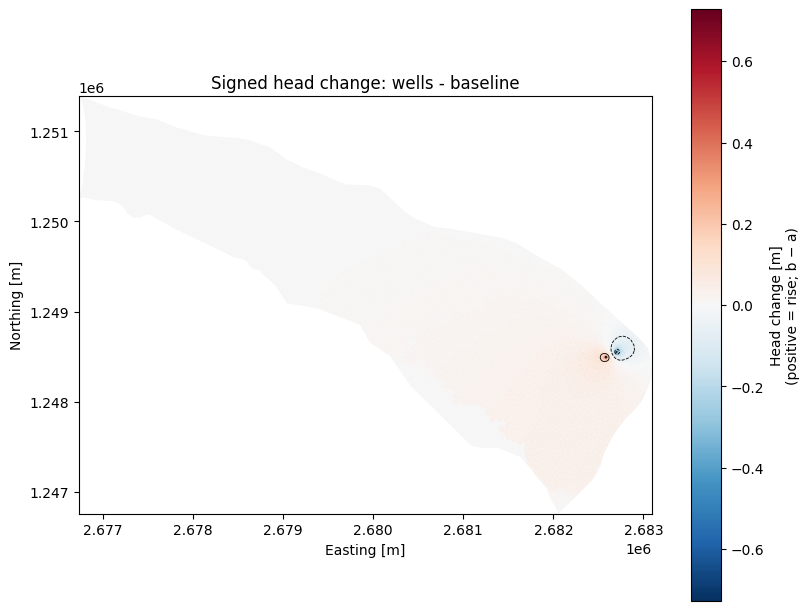

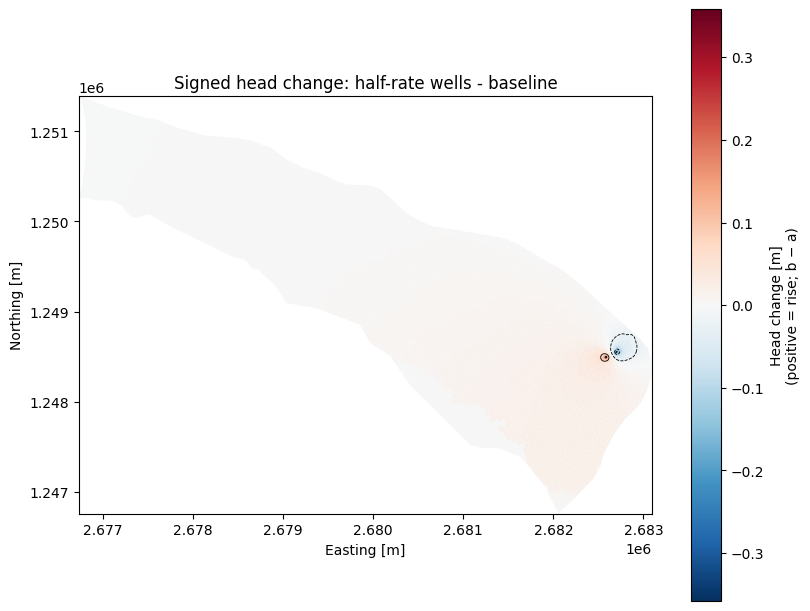

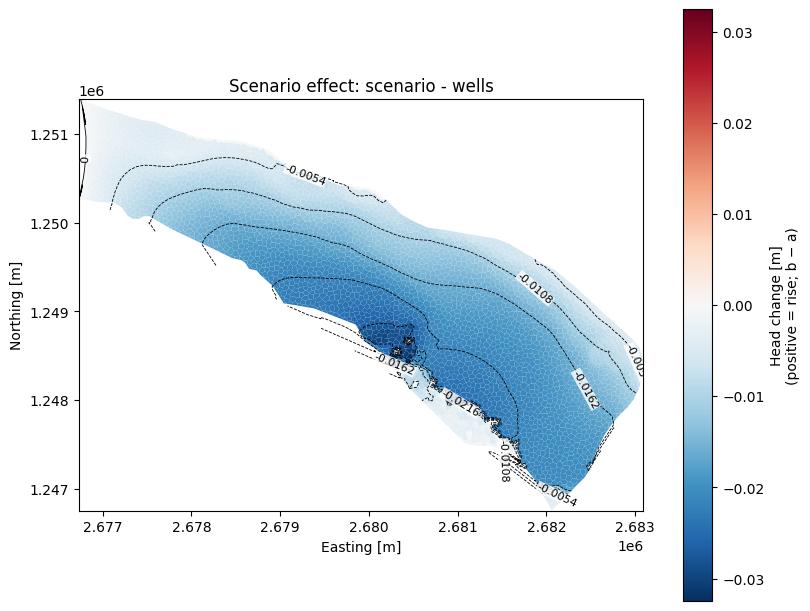

In [8]:
fig, ax = cfv.plot_difference_map(
    states["wells_only"], states["baseline"], title="Signed head change: wells - baseline",
)
cfv.save_fig(fig, "drawdown_wells", out_dir=work_dir)

fig, ax = cfv.plot_difference_map(
    states["wells_only_half"], states["baseline"], title="Signed head change: half-rate wells - baseline",
)
cfv.save_fig(fig, "drawdown_half", out_dir=work_dir)

fig, ax = cfv.plot_difference_map(
    states["wells_plus_scenario"], states["wells_only"], title="Scenario effect: scenario - wells",
)
cfv.save_fig(fig, "scenario_effect", out_dir=work_dir)


*Section 5 complete: head maps and the three signed head-change / scenario-effect difference maps are plotted and saved*

## 6. Water budget

A budget-bar plot per state (saved as one combined figure), plus a tidy
cross-state comparison table of signed net component fluxes
(`budget_components`) so you can read off, e.g., how RIV leakage changes
between `wells_only` and `wells_plus_scenario`.


WindowsPath('C:/Users/shado/applied_groundwater_modelling_data/limmat/case_study_group_04/figs/budget_states.png')

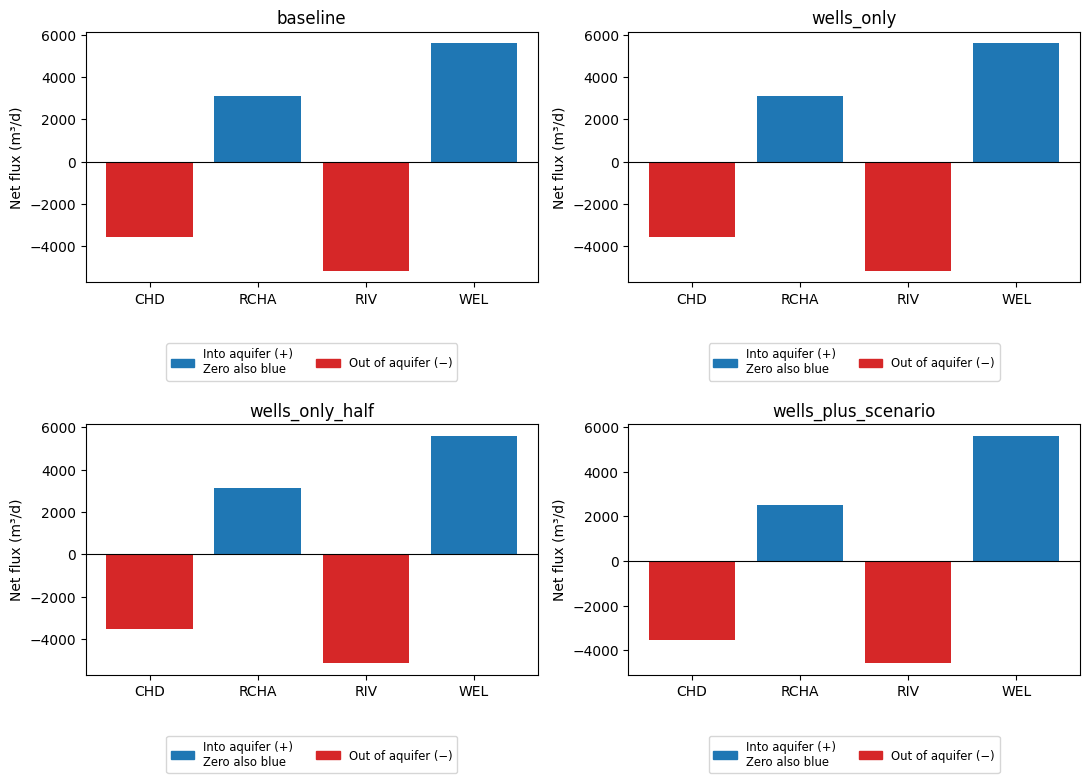

In [9]:
state_order = ["baseline", "wells_only", "wells_only_half", "wells_plus_scenario"]

fig, axes = plt.subplots(2, 2, figsize=(11, 8))
for state_name, ax in zip(state_order, axes.ravel()):
    cfv.plot_budget_bars(states[state_name], ax=ax)
    ax.set_title(state_name)
fig.tight_layout()
cfv.save_fig(fig, "budget_states", out_dir=work_dir)


In [10]:
budget_rows = []
for state_name in state_order:
    df = cfv.budget_components(states[state_name])
    df = df.copy()
    df["state"] = state_name
    budget_rows.append(df)

budget_comparison = pd.concat(budget_rows, ignore_index=True)
budget_comparison.pivot(index="component", columns="state", values="net_m3d")


state,baseline,wells_only,wells_only_half,wells_plus_scenario
component,,,,
CHD,-3551.495973,-3551.779692,-3551.293159,-3512.950772
RCHA,3117.513655,3117.513655,3117.513655,2494.010928
RIV,-5166.051069,-5164.400148,-5162.281007,-4580.459224
WEL,5602.723695,5602.723695,5602.723695,5602.723695


*Section 6 complete: per-state budget bars are saved; a cross-state signed-component comparison table is built*

## 7. Capture zone and pathlines

> **Boundary (read this before enabling `RUN_PRT`): this section is
> ADVECTIVE flow-field tracking only.** Capture = advective
> connection/timing between the wells under the *steady* flow field, given a
> chosen porosity. It is **not** a concentration/exceedance boundary, and it
> does **not** account for dispersion across streamtubes, sorption, or decay
> — those are the reactive-transport layer (module 08t / the M3 track), which
> uses a completely different (ADE) engine. Do not carry conclusions from
> this section directly over to a solute-transport claim.

Two runs on `states['wells_only']`:
- **`mode='forward'`** releases particles at the **injection** well and tracks
  forward → `connection_summary` reports the advective connection fraction
  and mean travel time to the **extraction** well (a recirculation check).
- **`mode='backward'`** releases particles at the **extraction** well and
  tracks on the **reversed** head/budget files → `capture_zone_summary`
  describes the shape/extent of the traced capture envelope.

Porosity defaults from the transport config (`porosity: 0.20` for group 0)
with recorded provenance — shown below.

This is an MF6 PRT run (a few seconds on the steady field) and it is
**required**: advective capture and travel time are core applied-modelling
results, and scratch Card B is built on the summary this section writes.
`RUN_PRT = True` by default. You may set it `False` while iterating on the
sections above, but **the run you submit must have it `True`** — otherwise
`pathlines_summary.csv` never reaches the bundle and Card B has no input.



PRT completed: 194 particles tracked
  Captured by well: 0
  Reached river:    0
  Other termination: 194
Forward (injection -> extraction) connection summary: {'advective_connection_fraction': 0.5927835051546392, 'n_released': 194, 'n_reached_extraction': 115, 'n_dropped': 6, 'mean_travel_time_d_to_extraction': 14.702562055769059}
Porosity provenance: {'value': 0.2, 'source': 'config', 'file': 'C:\\Users\\shado\\OneDrive\\Dokumente\\3 Schule\\UZH\\Semester 9 HS26\\Groundwater\\Group4_applied_groundwater_modelling\\PROJECT\\workspace\\template\\case_config_transport.yaml', 'key': 'transport_scenarios.options[id=4].transport.porosity', 'group': 4, 'config_hash': 'b009c7437a8c6d4b320744a9f4237fae497091fae53ace21187958487ffa732b'}
PRT completed: 198 particles tracked
  Captured by well: 0
  Reached river:    0
  Other termination: 198
Backward capture-zone summary: {'capture_zone_pathline_count': 198, 'max_backtrack_time_d': 490.0115169323047, 'envelope_note': 'Envelope = the scatter/hull

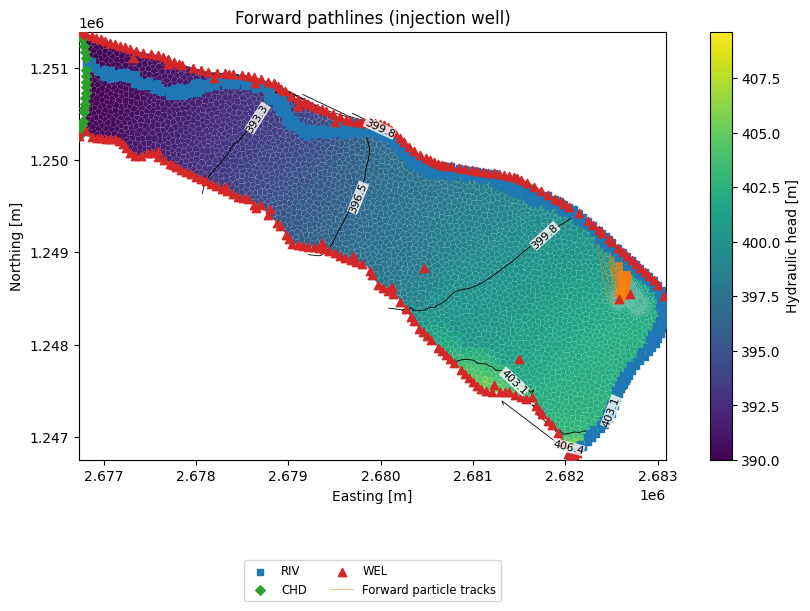

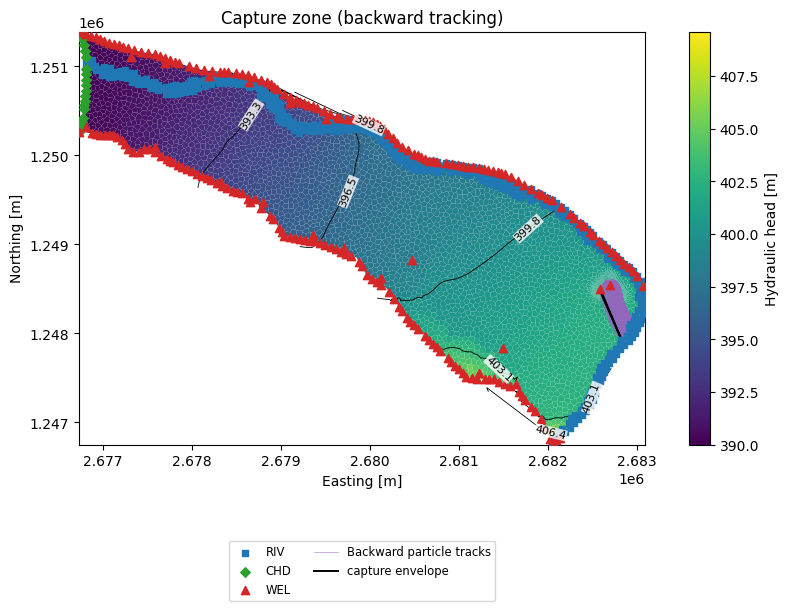

In [11]:
RUN_PRT = True  # REQUIRED for submission (feeds pathlines_summary.csv -> scratch Card B).
                # You may set False while iterating, but set it back before your final run.

if RUN_PRT:
    forward = cfp.build_capture(states["wells_only"], mode="forward", work_dir=work_dir)
    extc = states["wells_only"]["doublet"]["extraction"]["cell"]
    conn = cfp.connection_summary(forward, extc)
    print("Forward (injection -> extraction) connection summary:", conn)
    print("Porosity provenance:", forward["porosity_provenance"])

    backward = cfp.build_capture(states["wells_only"], mode="backward", work_dir=work_dir)
    capzone = cfp.capture_zone_summary(backward)
    print("Backward capture-zone summary:", capzone)

    fig, ax = cfp.plot_pathlines(states["wells_only"], forward, title="Forward pathlines (injection well)")
    cfv.save_fig(fig, "pathlines_forward", out_dir=work_dir)

    fig, ax = cfp.plot_capture_zone(states["wells_only"], backward)
    cfv.save_fig(fig, "capture_zone_backward", out_dir=work_dir)

    # Persist the two summaries so the steward export can carry them into the
    # exports/ bundle as pathlines_summary.csv (scratch Card B). Without this
    # the numbers exist only in this notebook's output and Card B has no input.
    #
    # advective_connection_fraction and n_dropped are DELIBERATELY not exported:
    # connection_summary's own docstring records that the fraction is a property
    # of the RELEASE DISC (its radius, and how many release points fell off-grid),
    # NOT of the doublet -- bar-charting it would teach something false.
    prt_summary = {
        "group": int(group_number),
        "mean_travel_time_d_to_extraction": conn["mean_travel_time_d_to_extraction"],
        "n_reached_extraction": conn["n_reached_extraction"],
        "n_released": conn["n_released"],
        "max_backtrack_time_d": capzone["max_backtrack_time_d"],
        "capture_zone_pathline_count": capzone["capture_zone_pathline_count"],
        "porosity_provenance": str(forward["porosity_provenance"]),
    }
    _prt_json = Path(work_dir) / f"prt_summary.group{int(group_number)}.json"
    _prt_json.write_text(json.dumps(prt_summary, indent=2) + "\n")
    print("wrote", _prt_json.name)
else:
    print("RUN_PRT is False -- skipping the PRT capture-zone analysis (flip to True to run it).")


*Section 7 complete: PRT capture-zone/pathline analysis is REQUIRED (RUN_PRT = True for the submitted run); the advective-only boundary is documented*

## 8. Metrics — you compute these

You hand-compose your group's **3–5 metrics** from the provided primitives
(`heads_of`, `difference`, `cell_areas`, `active_domain_mask`,
`free_head_mask`, `budget_components`) — there is no black-box "compute all
metrics" function; the point is that *you* decide what to mask and how to
combine primitives, and can justify it.

**Group 0 worked one-liners** (for reference — your metrics may differ):

> **Two head-change numbers, and they answer different questions.** The metrics
> below take `abs()`, so on a balanced injection/extraction doublet they count
> the injection **mound** as well as the extraction **cone**. The scratch
> analysis Card A instead reports *drawdown* proper — `base - wells`, positive
> only where the head falls.
>
> How far apart they land depends entirely on your scenario, and the spread
> across the 13 groups is wide: for some the two areas are within a few percent,
> for others they differ several-fold, and for one the drawdown area is **zero**
> while the `abs()` area is not — the mound clears 0.5 m where the cone never
> does. For several groups **both are zero**, because the doublet never moves the
> head by 0.5 m anywhere; that is a real result about your scenario, not a bug.
>
> So do not assume a relationship — **compute both and look**. *How much did this
> well field disturb the aquifer* and *how far does drawdown extend* are different
> questions, and which one you should quote depends on what you were asked.

In [12]:
# max |head change| (m), wells_only vs baseline, over FREE (active, non-CHD) cells --
# CHD cells are pinned and must be excluded from any head-change metric.
free = cfv.free_head_mask(states["baseline"])
dd_wells = cfv.difference(states["wells_only"], states["baseline"])
max_abs_head_change_m = np.nanmax(np.abs(dd_wells[free]))
print(f"max_abs_head_change_m (wells vs baseline) = {max_abs_head_change_m:.3f} m")

# area (m2) where |head change| > 0.5 m, area-weighted over free cells (NOT the
# broad active-area rule -- free_head_mask + cell_areas together).
areas = cfv.cell_areas(states["baseline"])
area_abs_head_change_gt_0p5m_m2 = float(areas[free][np.abs(dd_wells[free]) > 0.5].sum())
print(f"area_abs_head_change_gt_0p5m_m2 = {area_abs_head_change_gt_0p5m_m2:.1f} m2")

# a discharge-component change (m3/d): RIV net flux, wells_only vs baseline
# (budget_components is whole-model signed -- no cell mask).
riv_base = cfv.budget_components(states["baseline"]).set_index("component")["net_m3d"]["RIV"]
riv_wells = cfv.budget_components(states["wells_only"]).set_index("component")["net_m3d"]["RIV"]
river_leakage_change_m3d = riv_wells - riv_base
print(f"river_leakage_change_m3d (wells vs baseline) = {river_leakage_change_m3d:.2f} m3/d")


max_abs_head_change_m (wells vs baseline) = 0.728 m
area_abs_head_change_gt_0p5m_m2 = 240.5 m2
river_leakage_change_m3d (wells vs baseline) = 1.65 m3/d


**TODO**: compute your own group's 3–5 metrics for **your** assigned
comparison(s) (e.g. `wells_plus_scenario` vs `wells_only` for the scenario
effect, or the half-rate sensitivity). Build a `rows` list of
`{"name", "value", "unit"}` dicts and write them out.


In [13]:
# TODO: replace with your group's own 3-5 metrics (rows of {name, value, unit}).
rows = [
    {"name": "max_abs_head_change_m", "value": max_abs_head_change_m, "unit": "m"},
    {"name": "area_abs_head_change_gt_0p5m_m2", "value": area_abs_head_change_gt_0p5m_m2, "unit": "m2"},
    {"name": "river_leakage_change_m3d", "value": river_leakage_change_m3d, "unit": "m3/d"},
    # TODO: add 0-2 more metrics of your own choosing.
]

metrics_df = cfv.summarize_metrics(rows)
metrics_df


,name,value,unit
0,max_abs_head_change_m,0.727671,m
1,area_abs_head_change_gt_0p5m_m2,240.475116,m2
2,river_leakage_change_m3d,1.650921,m3/d


In [14]:
written = cfv.write_flow_metrics(group_number, rows, out_dir=work_dir)
print(f"Wrote: {written['csv']}")
print(f"Wrote: {written['json']}")


Wrote: C:\Users\shado\applied_groundwater_modelling_data\limmat\case_study_group_04\flow_metrics.group4.csv
Wrote: C:\Users\shado\applied_groundwater_modelling_data\limmat\case_study_group_04\flow_metrics.group4.json


### Cross-check: the equalization JSON

`emit_equalization_json` computes+writes `equalization_metrics.<group>.json`
from the `wells_plus_scenario` state's own state-iii return (the builder does
not auto-write this). It is the **authoritative cross-check for exactly two**
of the required reporting quantities — `river_leakage_change` and `gradient_change` —
**not** "the answers" for your other metrics above; it exists so you can
verify those two specific values independently of your own hand-computation.


In [15]:
equalization = cfv.emit_equalization_json(
    group_number, states["wells_plus_scenario"], out_dir=work_dir,
)
print(json.dumps(equalization, indent=2))


{
  "river_leakage_change": {
    "unit": "m3/d or %",
    "aggregation": "scalar",
    "baseline_convention": "wells-only vs wells-plus-scenario",
    "producer": "emit-obligation:M2a",
    "state_pair": [
      "wells_only",
      "wells_plus_scenario"
    ],
    "provenance_input_ids": [
      "river_to_aquifer_flux"
    ],
    "value": 583.94092346659,
    "pct_of_state_ii": 11.307042575186319
  },
  "gradient_change": {
    "unit": "- or %",
    "aggregation": "scalar",
    "baseline_convention": "wells-only vs wells-plus-scenario",
    "producer": "emit-obligation:M2a",
    "state_pair": [
      "wells_only",
      "wells_plus_scenario"
    ],
    "provenance_input_ids": [
      "gradient_inputs"
    ],
    "receptor_type": "river",
    "value": -2.6092943644676417e-05,
    "grad_ii": -0.0017812362237986017,
    "grad_iii": -0.001807329167443278,
    "dist_m": 216.36338337632054
  },
  "runtime": {
    "unit": "s",
    "aggregation": "scalar",
    "baseline_convention": "not_appl

*Section 8 complete: primitives + worked one-liners are shown; the student metrics + flow_metrics artifact + the equalization cross-check are wired*

## 9. Scenario sandbox (exploratory, NOT graded)

`explore_scenario` lets you vary your scenario's parameter freely — beyond
the single value fixed by your group assignment — to build intuition for
sensitivity. It keeps all physics gates (convergence, finite heads, mass
balance, no dry cells, same-grid) but **bypasses the frozen-expectation
gate**, since a sandbox exploration is allowed to disagree with the "expected
direction" table.

**This section is exploratory and NOT graded.** Sandbox runs write into an
isolated `_sandbox/` subfolder — they never touch `case_config.yaml` or the
required `flow_metrics.group<N>` artifact from Section 8.

**Worked example** (group 0's `chd_head_change` type, varying the magnitude
beyond the assigned -1 m):


Building refined Voronoi grid...
Refined grid: 4371 cells
CHD cells: 18


faithful RIV: reach (0, 2102) retains 1.4% of footprint after overbank filter (< 25%) -- conductance concentrated onto 1 cell(s)


RIV cells: 2602 (records: 2602, Sigma cond: 150332.3)
WEL cells: 238


faithful RIV: reach (0, 2102) retains 1.4% of footprint after overbank filter (< 25%) -- conductance concentrated onto 1 cell(s)


writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model g4_base_ref...
    writing model name file...
    writing package disv...
    writing package npf...
    writing package ic...
    writing package rcha_0...
    writing package chd_0...
INFORMATION: maxbound in ('gwf6', 'chd', 'dimensions') changed to 18 based on size of stress_period_data
    writing package riv_0...
INFORMATION: maxbound in ('gwf6', 'riv', 'dimensions') changed to 2602 based on size of stress_period_data
    writing package wel_0...
INFORMATION: maxbound in ('gwf6', 'wel', 'dimensions') changed to 226 based on size of stress_period_data
    writing package oc...


[casestudy_flow_builder] SKIPPING grid-pin for group 4: committed golden was generated on Linux, building on Windows -- the Triangle/Voronoi mesh differs cross-platform, so this golden is a valid pin only on Linux. The authoritative Windows golden supersedes it here (M2a.5 hub / cross-platform regen).


Budget components found: 7
Reading budget for time = 1.0

Water Balance Summary:
  Total Inflow:  1,654,052.86 m3/d
  Total Outflow: 1,654,047.47 m3/d
  Discrepancy:   5.38 m3/d
  Percent Error: 0.0003%
writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model g4_wells...
    writing model name file...
    writing package disv...
    writing package npf...
    writing package ic...
    writing package rcha_0...
    writing package chd_0...
INFORMATION: maxbound in ('gwf6', 'chd', 'dimensions') changed to 18 based on size of stress_period_data
    writing package riv_0...
INFORMATION: maxbound in ('gwf6', 'riv', 'dimensions') changed to 2602 based on size of stress_period_data
    writing package wel_0...
INFORMATION: maxbound in ('gwf6', 'wel', 'dimensions') changed to 228 based on size of stress_period_data
    writing package oc...
Budget components found: 7
Reading budget for time = 1.0

Water Ba

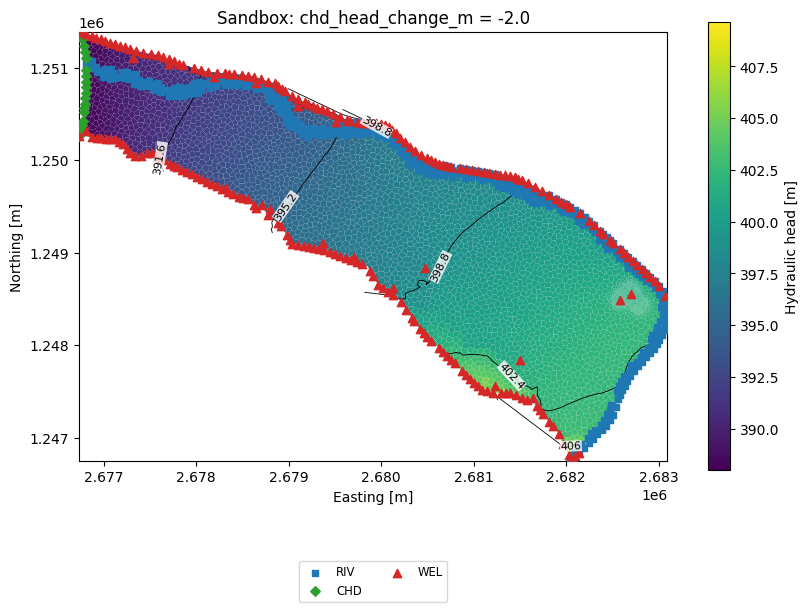

In [16]:
sandbox_result = cfv.explore_scenario(
    group_number, "chd_head_change", {"chd_head_change_m": -2.0},
    work_dir=work_dir,
)
print("exploratory:", sandbox_result["exploratory"])
fig, ax = cfv.plot_head_map(sandbox_result, title="Sandbox: chd_head_change_m = -2.0")


**TODO**: vary a parameter of **your own** scenario type (see the table
in Section 3 for the parameter name) and interpret the result — is the
system's response roughly linear in the parameter, or does it saturate/behave
non-linearly?


Building refined Voronoi grid...
Refined grid: 4371 cells
CHD cells: 18


faithful RIV: reach (0, 2102) retains 1.4% of footprint after overbank filter (< 25%) -- conductance concentrated onto 1 cell(s)


RIV cells: 2602 (records: 2602, Sigma cond: 150332.3)
WEL cells: 238


faithful RIV: reach (0, 2102) retains 1.4% of footprint after overbank filter (< 25%) -- conductance concentrated onto 1 cell(s)


writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model g4_base_ref...
    writing model name file...
    writing package disv...
    writing package npf...
    writing package ic...
    writing package rcha_0...
    writing package chd_0...
INFORMATION: maxbound in ('gwf6', 'chd', 'dimensions') changed to 18 based on size of stress_period_data
    writing package riv_0...
INFORMATION: maxbound in ('gwf6', 'riv', 'dimensions') changed to 2602 based on size of stress_period_data
    writing package wel_0...
INFORMATION: maxbound in ('gwf6', 'wel', 'dimensions') changed to 226 based on size of stress_period_data
    writing package oc...


[casestudy_flow_builder] SKIPPING grid-pin for group 4: committed golden was generated on Linux, building on Windows -- the Triangle/Voronoi mesh differs cross-platform, so this golden is a valid pin only on Linux. The authoritative Windows golden supersedes it here (M2a.5 hub / cross-platform regen).


Budget components found: 7
Reading budget for time = 1.0

Water Balance Summary:
  Total Inflow:  1,654,052.86 m3/d
  Total Outflow: 1,654,047.47 m3/d
  Discrepancy:   5.38 m3/d
  Percent Error: 0.0003%
writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model g4_wells...
    writing model name file...
    writing package disv...
    writing package npf...
    writing package ic...
    writing package rcha_0...
    writing package chd_0...
INFORMATION: maxbound in ('gwf6', 'chd', 'dimensions') changed to 18 based on size of stress_period_data
    writing package riv_0...
INFORMATION: maxbound in ('gwf6', 'riv', 'dimensions') changed to 2602 based on size of stress_period_data
    writing package wel_0...
INFORMATION: maxbound in ('gwf6', 'wel', 'dimensions') changed to 228 based on size of stress_period_data
    writing package oc...
Budget components found: 7
Reading budget for time = 1.0

Water Ba

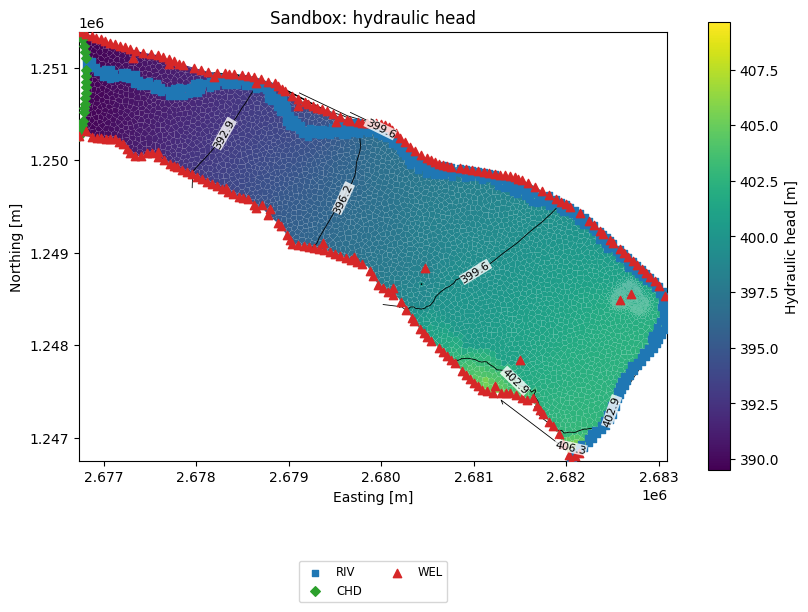

In [17]:
# TODO: replace scenario_type/params with your group's own scenario type + a
# parameter value you want to explore.
my_sandbox_result = cfv.explore_scenario(
    group_number, "chd_head_change", {"chd_head_change_m": -0.5},  # TODO: your parameter
    work_dir=work_dir,
)
fig, ax = cfv.plot_head_map(my_sandbox_result, title="Sandbox: hydraulic head")


*Section 9 complete: the sandbox seam is demonstrated (exploratory, isolated, not graded); a student TODO variant is scaffolded*

## 10. Interpretation and defensibility

These are **report** deliverables first — they are the raw material for the report's
limitations section (see [`REPORT_BRIEF.md`](REPORT_BRIEF.md) §5) — and then for your
presentation. Carry your answers there, not (only) here.

**TODO (priority 1) — which results are defensible vs. artifacts?**
For each map/metric you are relying on: is it a robust physical response, or
could it be sensitive to a modelling choice you made (grid refinement radius,
release-disc radius for particle tracking, the mask you chose for a metric,
a scenario parameter that was arbitrarily chosen)? Name at least one result
you would flag as an artifact risk and explain why.

**TODO (priority 2) — justify your assumptions.**
Revisit the BC/parameter-change justification from Section 3 and your metric
choices from Section 8: are they reasonable simplifications of the real
story? What would you check first if you had more data or more time?


*Section 10 complete: the interpretation and defensibility prompts are set as report and presentation deliverables*

## 11. Reproducibility check

A clean re-run from `case_config.yaml`, into a **second** work directory,
should reproduce your key metrics within a small tolerance. This guards
against silent nondeterminism (e.g. solver tolerance noise) creeping into
your reported numbers.


In [18]:
repro_work_dir = work_dir.parent / f"{work_dir.name}_repro_check"
repro_work_dir.mkdir(parents=True, exist_ok=True)

repro_states = cfb.build_all_flow_states(group_number, work_dir=repro_work_dir)

repro_free = cfv.free_head_mask(repro_states["baseline"])
repro_dd_wells = cfv.difference(repro_states["wells_only"], repro_states["baseline"])
repro_max_abs_head_change_m = np.nanmax(np.abs(repro_dd_wells[repro_free]))

tol_m = 1e-6
assert abs(repro_max_abs_head_change_m - max_abs_head_change_m) < tol_m, (
    f"reproducibility check FAILED: {repro_max_abs_head_change_m} vs {max_abs_head_change_m} "
    f"(tol={tol_m} m)"
)
print(
    f"Reproducibility OK: max_abs_head_change_m = {max_abs_head_change_m:.6f} m "
    f"(re-run: {repro_max_abs_head_change_m:.6f} m, within {tol_m} m)"
)


Building refined Voronoi grid...
Refined grid: 4371 cells
CHD cells: 18


faithful RIV: reach (0, 2102) retains 1.4% of footprint after overbank filter (< 25%) -- conductance concentrated onto 1 cell(s)


RIV cells: 2602 (records: 2602, Sigma cond: 150332.3)
WEL cells: 238


faithful RIV: reach (0, 2102) retains 1.4% of footprint after overbank filter (< 25%) -- conductance concentrated onto 1 cell(s)


writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model g4_base_ref...
    writing model name file...
    writing package disv...
    writing package npf...
    writing package ic...
    writing package rcha_0...
    writing package chd_0...
INFORMATION: maxbound in ('gwf6', 'chd', 'dimensions') changed to 18 based on size of stress_period_data
    writing package riv_0...
INFORMATION: maxbound in ('gwf6', 'riv', 'dimensions') changed to 2602 based on size of stress_period_data
    writing package wel_0...
INFORMATION: maxbound in ('gwf6', 'wel', 'dimensions') changed to 226 based on size of stress_period_data
    writing package oc...


[casestudy_flow_builder] SKIPPING grid-pin for group 4: committed golden was generated on Linux, building on Windows -- the Triangle/Voronoi mesh differs cross-platform, so this golden is a valid pin only on Linux. The authoritative Windows golden supersedes it here (M2a.5 hub / cross-platform regen).


Budget components found: 7
Reading budget for time = 1.0

Water Balance Summary:
  Total Inflow:  1,654,052.86 m3/d
  Total Outflow: 1,654,047.47 m3/d
  Discrepancy:   5.38 m3/d
  Percent Error: 0.0003%
writing simulation...
  writing simulation name file...
  writing simulation tdis package...
  writing solution package ims_-1...
  writing model g4_wells...
    writing model name file...
    writing package disv...
    writing package npf...
    writing package ic...
    writing package rcha_0...
    writing package chd_0...
INFORMATION: maxbound in ('gwf6', 'chd', 'dimensions') changed to 18 based on size of stress_period_data
    writing package riv_0...
INFORMATION: maxbound in ('gwf6', 'riv', 'dimensions') changed to 2602 based on size of stress_period_data
    writing package wel_0...
INFORMATION: maxbound in ('gwf6', 'wel', 'dimensions') changed to 228 based on size of stress_period_data
    writing package oc...
Budget components found: 7
Reading budget for time = 1.0

Water Ba

*Section 11 complete: a from-config clean re-run reproduces the key metric within a stated tolerance*